# Mini-Project 1 – UBOS District Population Forecaster

**OOP with Python, Assignment 1 (Advent 2026)** · Wesonga John Collins

A district planning unit wants 5-year population forecasts to plan primary-school classrooms. This notebook
analyses five districts, compares three forecasting models on held-out years, forecasts 2025–2029 and
converts the forecasts into classroom requirements.

Reusable logic lives in `src/a1/` (`population.py`, `forecasting.py`, `metrics.py`) and is unit-tested in `tests/`.
This notebook only orchestrates, displays and interprets.

## 0. Setup

In [1]:
from pathlib import Path
import statistics

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from a1.forecasting import (
    CAGRForecaster,
    FibonacciRatioForecaster,
    LinearTrendForecaster,
    bootstrap_intervals,
    fibonacci_ratios,
)
from a1.metrics import evaluate
from a1.population import DistrictForecastStudy, DistrictPopulation

SEED = 2026                      # single seed for every random step (bootstrap)
LAST_TRAIN_YEAR = 2021           # train 2015-2021, test 2022-2024
HORIZON = 5                      # forecast 2025-2029
N_BOOT = 2000                    # bootstrap resamples (brief requires >= 1,000)
PRIMARY_SHARE = 0.18
CLASS_SIZE = 53

# Locate the repository root whether the notebook runs from notebooks/ or the root.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
pd.set_option("display.precision", 3)
print("Repository root:", ROOT)

Repository root: C:\Users\johnc\Projects\oop-python-assignment-1


## 1. Data and assumptions

`data/processed/population.csv` is produced by `scripts/build_population_data.py` from the raw UBOS files
(see `data/raw/population/SOURCES.md`). Every row carries a `source` label.

| District | Source |
|---|---|
| Kampala, Wakiso, Gulu | Illustrative values given in the assignment brief (thousands) |
| Jinja, Busia | UBOS mid-year projections 2015–2021; NPHC 2024 census count for 2024; 2022–2023 geometrically interpolated |

Key assumptions (discussed again in *Findings & Limitations*):

1. All values are mid-year populations in thousands; the real districts were converted from persons.
2. **Jinja 2024 = Jinja District + Jinja City**, to keep the pre-2020 boundary used by the projections.
3. **Jinja and Busia 2022–2023 are interpolated** at a constant growth rate between the 2021 projection and
   the 2024 census. They are not observations, so a second evaluation on 2024 alone is also reported.
4. 2015–2021 UBOS figures are projections from the 2014 census, while 2024 is a census count; the two kinds
   of figure need not lie on one smooth path.

In [2]:
data = pd.read_csv(ROOT / "data" / "processed" / "population.csv")

districts = {
    name: DistrictPopulation(
        name, g["year"], g["population_thousands"], sources=g["source"].tolist()
    )
    for name, g in data.groupby("district", sort=False)
}

print(data["source"].value_counts().to_string(), "\n")
data.pivot(index="year", columns="district", values="population_thousands")

source
illustrative (assignment brief)      30
UBOS mid-year projection             14
geometric interpolation 2021-2024     4
NPHC 2024 census                      2 



district,Busia,Gulu,Jinja,Kampala,Wakiso
year,,,,,
2015,331.400,320.0,476.800,1200.0,950.0
2016,341.500,330.0,484.600,1250.0,1000.0
2017,351.900,345.0,492.400,1300.0,1070.0
2018,362.500,360.0,500.100,1350.0,1150.0
2019,373.200,375.0,507.700,1420.0,1220.0
2020,384.000,390.0,515.100,1500.0,1300.0
2021,394.900,410.0,522.300,1580.0,1390.0
2022,400.737,430.0,534.604,1650.0,1480.0
2023,406.660,455.0,547.198,1720.0,1570.0


## 2. Task 1 – the `DistrictPopulation` class

Each district is a `DistrictPopulation` object holding years and populations as read-only NumPy arrays.
The constructor validates the input (equal lengths and no negative values, as the brief requires, plus empty
input, NaN, non-whole and non-consecutive years). Below: `__repr__`, `__len__`, and validation in action.

In [3]:
for d in districts.values():
    print(repr(d), "| len =", len(d))

bad_inputs = {
    "unequal lengths": ([2015, 2016, 2017], [100, 110]),
    "negative population": ([2015, 2016], [100, -5]),
    "empty input": ([], []),
}
for label, (yrs, pops) in bad_inputs.items():
    try:
        DistrictPopulation("Test", yrs, pops)
    except ValueError as err:
        print(f"Rejected ({label}): {err}")

DistrictPopulation('Kampala', years=2015-2024, n=10, unit='thousands') | len = 10
DistrictPopulation('Wakiso', years=2015-2024, n=10, unit='thousands') | len = 10
DistrictPopulation('Gulu', years=2015-2024, n=10, unit='thousands') | len = 10
DistrictPopulation('Jinja', years=2015-2024, n=10, unit='thousands') | len = 10
DistrictPopulation('Busia', years=2015-2024, n=10, unit='thousands') | len = 10
Rejected (unequal lengths): length mismatch: 3 years vs 2 populations
Rejected (negative population): populations must not be negative
Rejected (empty input): years and populations must not be empty


## 3. Task 2 – descriptive statistics with `statistics` and NumPy

**Why the variances differ.** `statistics.variance` is the *sample* variance, dividing the sum of squared
deviations by *n − 1*. `np.var` divides by *n − ddof*, and `ddof` defaults to 0, giving the *population*
variance. Dividing by *n − 1* (Bessel's correction) compensates for measuring deviations from the sample
mean, which is itself estimated from the same data. With `ddof=1`, NumPy matches `statistics` exactly; with
n = 10 the sample variance is 10/9 ≈ 1.11 times the population variance.

In [4]:
rows = []
for name, d in districts.items():
    s = d.stats_statistics()
    n0 = d.stats_numpy(ddof=0)
    n1 = d.stats_numpy(ddof=1)
    rows.append({
        "district": name,
        "mean": s["mean"],
        "median": s["median"],
        "var (statistics)": s["variance"],
        "var (np, ddof=0)": n0["variance"],
        "var (np, ddof=1)": n1["variance"],
        "sd (statistics)": s["stdev"],
        "sd (np, ddof=0)": n0["stdev"],
        "ratio var stats/np0": s["variance"] / n0["variance"],
    })
stats_table = pd.DataFrame(rows).set_index("district")

# Second-method check: statistics and NumPy (ddof=1) must agree.
assert np.allclose(stats_table["var (statistics)"], stats_table["var (np, ddof=1)"])
stats_table

,mean,median,var (statistics),"var (np, ddof=0)","var (np, ddof=1)",sd (statistics),"sd (np, ddof=0)",ratio var stats/np0
district,,,,,,,,
Kampala,1477.000,1460.0,42601.111,38341.000,42601.111,206.400,195.809,1.111
Wakiso,1280.000,1260.0,60066.667,54060.000,60066.667,245.085,232.508,1.111
Gulu,389.500,382.5,2885.833,2597.250,2885.833,53.720,50.963,1.111
Jinja,514.089,511.4,740.945,666.851,740.945,27.220,25.823,1.111
Busia,375.947,378.6,807.579,726.821,807.579,28.418,26.960,1.111


`statistics.variance` and `np.var(..., ddof=1)` agree exactly for every district, and both exceed the default `np.var` (ddof=0) by the factor 10/9 ≈ 1.111 expected for n = 10. Variance is measured in thousands² and is dominated by each district's trend over the decade: Wakiso's variance (60,067) is the largest because it added the most people, not because its population fluctuates. For trending series these statistics describe how far the series travelled, not volatility, and they cannot be compared across districts of different size.

## 4. Task 3 – growth rates and CAGR

Year-on-year growth: $g_t = (P_t - P_{t-1}) / P_{t-1}$. Compound annual growth rate over 2015–2024
(**9 intervals**): $\text{CAGR} = (P_{2024}/P_{2015})^{1/9} - 1$.

In [5]:
yoy = pd.DataFrame(
    {name: d.yoy_growth() * 100 for name, d in districts.items()},
    index=[f"{y-1}-{y}" for y in range(2016, 2025)],
)
growth_summary = pd.DataFrame({
    "CAGR 2015-2024 (%)": {n: d.cagr() * 100 for n, d in districts.items()},
    "mean YoY (%)": yoy.mean(),
    "min YoY (%)": yoy.min(),
    "max YoY (%)": yoy.max(),
}).sort_values("CAGR 2015-2024 (%)", ascending=False)

# Hand check from the brief's data: Kampala (1800/1200)^(1/9) - 1 = 4.608 %
assert abs(districts["Kampala"].cagr() - (1.5 ** (1 / 9) - 1)) < 1e-12

display(yoy.round(2))
growth_summary.round(3)

,Kampala,Wakiso,Gulu,Jinja,Busia
2015-2016,4.17,5.26,3.12,1.64,3.05
2016-2017,4.00,7.00,4.55,1.61,3.05
2017-2018,3.85,7.48,4.35,1.56,3.01
2018-2019,5.19,6.09,4.17,1.52,2.95
2019-2020,5.63,6.56,4.00,1.46,2.89
2020-2021,5.33,6.92,5.13,1.40,2.84
2021-2022,4.43,6.47,4.88,2.36,1.48
2022-2023,4.24,6.08,5.81,2.36,1.48
2023-2024,4.65,6.37,5.49,2.36,1.48


,CAGR 2015-2024 (%),mean YoY (%),min YoY (%),max YoY (%)
Wakiso,6.469,6.470,5.263,7.477
Kampala,4.608,4.610,3.846,5.634
Gulu,4.608,4.611,3.125,5.814
Busia,2.467,2.469,1.478,3.048
Jinja,1.805,1.806,1.398,2.356


*Interpretation*
Wakiso is growing fastest in relative terms (CAGR 6.47 % a year), followed by Kampala and Gulu, which share an identical CAGR of 4.61 % because both grew by exactly 50 % between 2015 and 2024 despite a five-fold difference in size. Busia (2.47 %) and Jinja (1.81 %) grow more slowly. The mean of the year-on-year rates is marginally above each CAGR, as expected, because an arithmetic mean is never below a geometric mean. Gulu's annual rates vary more (3.1–5.8 %) than Kampala's. For Jinja and Busia, the identical 2021–2024 rates (2.36 % and 1.48 %) are a by-product of the geometric interpolation. They show that the 2024 census lies above UBOS's projected path for Jinja and below it for Busia, rather than describing growth in individual years.

## 5. Task 4 – three forecasting models

All three are subclasses of the abstract `Forecaster` base class (`fit(values)` then `predict(horizon)`):

* **Linear trend** – least-squares line $\hat P = a + b\,t$ (`np.polyfit`, degree 1): constant *absolute* growth.
* **CAGR** – $\hat P_{T+h} = P_T (1+g)^h$, with $g$ the CAGR of the training series: constant *percentage* growth.
* **Fibonacci ratio** (previous cohort's method) – $\hat P_{T+h} = P_T \prod_{k=1}^{h} F_{n+k}/F_{n+k-1}$,
  with start index $n = 1$ (ratios 1/1, 2/1, 3/2, 5/3, …). Nothing is estimated from the data.

In [6]:
MODELS = [LinearTrendForecaster(), CAGRForecaster(), FibonacciRatioForecaster(start_index=1)]
for m in MODELS:
    print(m)
print("First Fibonacci ratios (n=1):", np.round(fibonacci_ratios(1, 6), 4))

LinearTrendForecaster(fitted=False)
CAGRForecaster(fitted=False)
FibonacciRatioForecaster(start_index=1, fitted=False)
First Fibonacci ratios (n=1): [1.     2.     1.5    1.6667 1.6    1.625 ]


## 6. Task 5 – validate before forecasting (train 2015–2021, test 2022–2024)

Each model is fitted on 2015–2021 only and scored on 2022–2024. The selection criterion, fixed before
looking at results, is **RMSE** (it penalises large misses, which matter most for planning). MAE and MAPE are
reported alongside.

In [7]:
studies = {name: DistrictForecastStudy(d, MODELS, LAST_TRAIN_YEAR) for name, d in districts.items()}

best = {}
for name, study in studies.items():
    table = pd.DataFrame(study.backtest()).T
    table.index.name = "model"
    best[name] = study.best_model("RMSE")
    print(f"\n{name}  (test years {study.test.years.tolist()}) - best by RMSE: {best[name]}")
    display(table.round(3))


Kampala  (test years [2022, 2023, 2024]) - best by RMSE: CAGR


,MAE,RMSE,MAPE
model,,,
Linear trend,37.619,38.975,2.165
CAGR,9.619,10.385,0.551
Fibonacci ratio,1483.333,1890.511,83.766



Wakiso  (test years [2022, 2023, 2024]) - best by RMSE: CAGR


,MAE,RMSE,MAPE
model,,,
Linear trend,49.405,52.368,3.094
CAGR,6.802,8.049,0.420
Fibonacci ratio,1266.667,1604.390,77.617



Gulu  (test years [2022, 2023, 2024]) - best by RMSE: CAGR


,MAE,RMSE,MAPE
model,,,
Linear trend,18.571,20.287,4.009
CAGR,9.437,10.869,2.025
Fibonacci ratio,378.333,481.707,80.374



Jinja  (test years [2022, 2023, 2024]) - best by RMSE: CAGR


,MAE,RMSE,MAPE
model,,,
Linear trend,9.440,10.332,1.711
CAGR,8.844,9.597,1.604
Fibonacci ratio,505.506,648.390,90.987



Busia  (test years [2022, 2023, 2024]) - best by RMSE: Linear trend


,MAE,RMSE,MAPE
model,,,
Linear trend,9.082,9.838,2.222
CAGR,12.094,13.132,2.959
Fibonacci ratio,387.002,497.614,94.251


In [8]:
# Does the choice depend on the metric?
agreement = pd.DataFrame({
    metric: {name: s.best_model(metric) for name, s in studies.items()}
    for metric in ("RMSE", "MAE", "MAPE")
})
agreement

,RMSE,MAE,MAPE
Kampala,CAGR,CAGR,CAGR
Wakiso,CAGR,CAGR,CAGR
Gulu,CAGR,CAGR,CAGR
Jinja,CAGR,CAGR,CAGR
Busia,Linear trend,Linear trend,Linear trend


In [9]:
# Jinja and Busia: 2022-2023 are interpolated, so also score each model on 2024 alone (a real census count).
rows = []
for name in ("Jinja", "Busia"):
    study = studies[name]
    actual_2024 = study.test.populations[-1]
    for model, pred in study.test_predictions().items():
        rows.append({
            "district": name,
            "model": model,
            "actual 2024": actual_2024,
            "predicted 2024": pred[-1],
            "abs error": abs(pred[-1] - actual_2024),
            "abs % error": abs(pred[-1] - actual_2024) / actual_2024 * 100,
        })
pd.DataFrame(rows).set_index(["district", "model"]).round(3)

actual 2024  predicted 2024  abs error  abs % error
district model                                                               
Jinja    Linear trend         560.089         545.457     14.632        2.612
         CAGR                 560.089         546.653     13.436        2.399
         Fibonacci ratio      560.089        1566.900   1006.811      179.759
Busia    Linear trend         412.671         426.371     13.700        3.320
         CAGR                 412.671         431.077     18.406        4.460
         Fibonacci ratio      412.671        1184.700    772.029      187.081

*Interpretation*
CAGR has the lowest test error in Kampala, Wakiso, Gulu and Jinja; the linear trend wins in Busia. RMSE, MAE and MAPE select the same model in every district, so the choice does not depend on the metric. The margins differ: in Kampala and Wakiso CAGR's RMSE is about a quarter or less of the linear trend's, whereas in Jinja they are close (9.6 vs 10.3 thousand), and three test years are weak evidence. The Fibonacci model misses by 78–94 % (MAPE). Scoring Jinja and Busia on the 2024 census alone gives the same ranking, so the interpolated years did not drive the selection. Every model under-predicts Jinja's 2024 population and over-predicts Busia's by 13–18 thousand: the census departed from the projected path in opposite directions. Linear wins in Busia because it extrapolates more conservatively when growth slowed, not because Busia's growth is inherently linear.

## 7. Task 6 – forecast 2025–2029 and compare variances

The selected model for each district is **refitted on all of 2015–2024** and used to forecast 2025–2029.
Variances use `statistics.variance` (sample variance) for both series.

In [10]:
forecasts = {}
rows = []
for name, study in studies.items():
    years_f, values_f = study.final_forecast(HORIZON, "RMSE")
    forecasts[name] = (years_f, values_f)
    var_actual = statistics.variance(study.district.populations.tolist())
    var_forecast = statistics.variance(values_f.tolist())
    rows.append({
        "district": name,
        "model": best[name],
        **{str(y): v for y, v in zip(years_f, values_f)},
        "var actual 2015-24": var_actual,
        "var forecast 2025-29": var_forecast,
        "ratio forecast/actual": var_forecast / var_actual,
    })
forecast_table = pd.DataFrame(rows).set_index("district")
forecast_table.round(3)

,model,2025,2026,2027,2028,2029,var actual 2015-24,var forecast 2025-29,ratio forecast/actual
district,,,,,,,,,
Kampala,CAGR,1882.947,1969.717,2060.486,2155.437,2254.763,42601.111,21607.682,0.507
Wakiso,CAGR,1778.025,1893.038,2015.491,2145.864,2284.671,60066.667,40131.362,0.668
Gulu,CAGR,502.119,525.258,549.463,574.783,601.270,2885.833,1536.546,0.532
Jinja,CAGR,570.198,580.490,590.968,601.635,612.494,740.945,279.533,0.377
Busia,Linear trend,427.272,436.603,445.935,455.267,464.599,807.579,217.705,0.270


*Interpretation.*
The forecast series has 27–67 % of the variance of the observed series. This does not mean the future is more predictable. A five-year forecast is a smooth curve covering half the span of the ten-year history, so its values are less spread out, and by construction it contains no year-to-year noise. The variance of a trending series measures how far the series travels, not uncertainty; uncertainty is addressed by the prediction intervals in Section 8.

## 8. Extension – bootstrap 95 % prediction intervals

Residual bootstrap with refitting (`bootstrap_intervals`, 2,000 resamples, seeded): each replicate adds
resampled residuals to the fitted values, refits the selected model, forecasts, and adds a resampled residual
to each future year. The 2.5th and 97.5th percentiles form the interval.

Residuals are **centred** (shifted to mean zero) before resampling. The CAGR fitted path passes exactly
through the first and last values, so its residuals need not average zero; uncentred, they would shift every
replicate in the same direction. The second cell below shows the effect for each district's 2029 interval.

In [11]:
rng = np.random.default_rng(SEED)
intervals = {}
rows = []
for name, study in studies.items():
    template = next(m for m in MODELS if m.name == best[name])
    point, lower, upper = bootstrap_intervals(
        template, study.district.populations, HORIZON, rng=rng, n_boot=N_BOOT
    )
    assert np.allclose(point, forecasts[name][1])        # same point forecast as Task 6
    intervals[name] = (lower, upper)
    rows.append({
        "district": name,
        "model": best[name],
        "2029 forecast": point[-1],
        "2029 lower 95%": lower[-1],
        "2029 upper 95%": upper[-1],
        "2029 width": upper[-1] - lower[-1],
    })
pd.DataFrame(rows).set_index("district").round(3)

,model,2029 forecast,2029 lower 95%,2029 upper 95%,2029 width
district,,,,,
Kampala,CAGR,2254.763,2207.390,2296.924,89.533
Wakiso,CAGR,2284.671,2253.698,2313.689,59.991
Gulu,CAGR,601.270,586.131,618.924,32.792
Jinja,CAGR,612.494,600.841,622.384,21.543
Busia,Linear trend,464.599,455.898,472.798,16.900


In [12]:
# Effect of centring: 2029 interval with and without it (same seed for both runs).
rows = []
for name, study in studies.items():
    template = next(m for m in MODELS if m.name == best[name])
    fitted_model = template.clone().fit(study.district.populations)
    for center in (False, True):
        _, lo, hi = bootstrap_intervals(template, study.district.populations, HORIZON,
                                        rng=np.random.default_rng(SEED), n_boot=N_BOOT,
                                        center=center)
        rows.append({"district": name, "centred": center,
                     "mean residual": fitted_model.residuals().mean(),
                     "2029 forecast": forecasts[name][1][-1],
                     "2029 lower": lo[-1], "2029 upper": hi[-1],
                     "interval midpoint - forecast": (lo[-1] + hi[-1]) / 2 - forecasts[name][1][-1]})
pd.DataFrame(rows).set_index(["district", "centred"]).round(3)

mean residual  2029 forecast  2029 lower  2029 upper  \
district centred                                                         
Kampala  False           -5.029       2254.763    2197.774    2287.399   
         True            -5.029       2254.763    2207.390    2296.924   
Wakiso   False           -0.074       2284.671    2253.469    2309.838   
         True            -0.074       2284.671    2253.603    2309.970   
Gulu     False           -5.708        601.270     575.022     607.958   
         True            -5.708        601.270     585.960     618.776   
Jinja    False           -3.363        612.494     594.132     615.710   
         True            -3.363        612.494     600.820     622.388   
Busia    False            0.000        464.599     456.257     472.864   
         True             0.000        464.599     456.257     472.864   

                  interval midpoint - forecast  
district centred                                
Kampala  False                         -12.177  
         True                           -2.606  
Wakiso   False                          -3.017  
         True                           -2.884  
Gulu     False                          -9.780  
         True                            1.098  
Jinja    False                          -7.573  
         True                           -0.890  
Busia    False                          -0.038  
         True                           -0.038

CAGR residuals average about −3.4 to −5.7 thousand for Kampala, Gulu and Jinja, because the fitted curve passes exactly through the first and last points while most intermediate values lie below it. Uncentred, this pulls the interval's midpoint 7.6–12.2 thousand below the forecast; centring reduces the gap to under 3 thousand with almost no change in width. Busia's linear residuals already average zero, so centring has no effect there. Even centred, the intervals are narrow: Busia's 2029 interval is 16.9 thousand wide, about the size of the 13.7 thousand error the linear model actually made for 2024. The intervals capture noise around a smooth trend, but not shifts such as a census revising the path, so they should be read as lower bounds on real uncertainty.

## 9. Task 7 – actual, fitted and forecast values

Solid line: data (hollow markers = interpolated years, star = 2024 census for Jinja and Busia). Dashed: the
selected model fitted on 2015–2021 and its 2022–2024 test predictions. Dotted: refitted forecast 2025–2029 (drawn from the 2024 value)
with the shaded 95 % bootstrap interval. The grey band marks the test period.

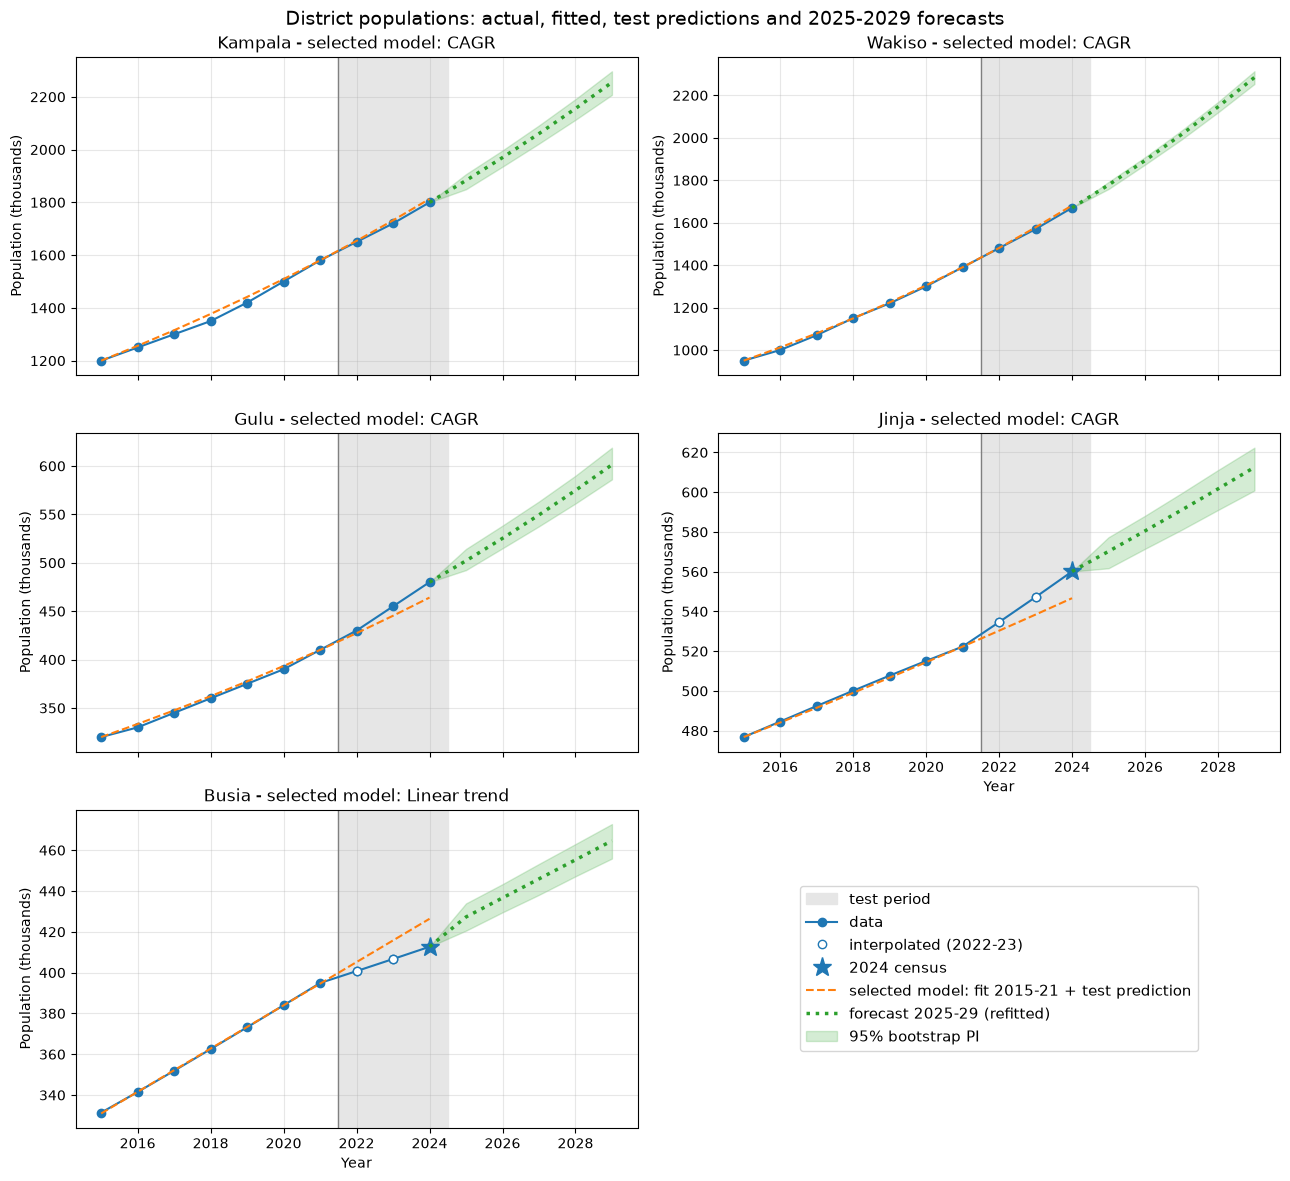

In [13]:
fig, axes = plt.subplots(3, 2, figsize=(13, 12), sharex=True)
axes = axes.ravel()

for ax, (name, study) in zip(axes, studies.items()):
    d = study.district
    src = np.array(d.sources)
    model = best[name]

    ax.axvspan(LAST_TRAIN_YEAR + 0.5, d.years[-1] + 0.5, color="0.9", label="test period")
    ax.axvline(LAST_TRAIN_YEAR + 0.5, color="0.5", lw=1)

    ax.plot(d.years, d.populations, "o-", color="tab:blue", label="data")
    interp = np.char.startswith(src.astype(str), "geometric")
    census = np.char.startswith(src.astype(str), "NPHC")
    if interp.any():
        ax.plot(d.years[interp], d.populations[interp], "o", mfc="white", color="tab:blue",
                label="interpolated (2022-23)")
    if census.any():
        ax.plot(d.years[census], d.populations[census], "*", ms=14, color="tab:blue",
                label="2024 census")

    fitted = study.train_fitted()[model]
    test_pred = study.test_predictions()[model]
    ax.plot(np.r_[study.train.years, study.test.years], np.r_[fitted, test_pred],
            "--", color="tab:orange", label="selected model: fit 2015-21 + test prediction")

    years_f, values_f = forecasts[name]
    lower, upper = intervals[name]
    # Start the forecast line and band at the last observation so the curve is continuous.
    yf = np.r_[d.years[-1], years_f]
    ax.plot(yf, np.r_[d.populations[-1], values_f], ":", lw=2.5, color="tab:green",
            label="forecast 2025-29 (refitted)")
    ax.fill_between(yf, np.r_[d.populations[-1], lower], np.r_[d.populations[-1], upper],
                    color="tab:green", alpha=0.2, label="95% bootstrap PI")

    ax.set_title(f"{name} - selected model: {model}")
    ax.set_ylabel("Population (thousands)")
    ax.grid(alpha=0.3)

for ax in axes[3:5]:                                         # bottom row of each column
    ax.set_xlabel("Year")
    ax.xaxis.set_tick_params(labelbottom=True)
handles, labels = axes[3].get_legend_handles_labels()       # Jinja panel has every marker type
axes[-1].axis("off")
axes[-1].legend(handles, labels, loc="center", fontsize=11)
fig.suptitle("District populations: actual, fitted, test predictions and 2025-2029 forecasts",
             fontsize=14)
fig.tight_layout()
plt.show()

*Interpretation.*
The selected models track the illustrative districts closely through the test period, while Jinja and Busia diverge from their fitted trends in opposite directions after 2021: Jinja's 2024 census lies above the model, Busia's below it. The 2025–2029 bands are visibly narrow compared with these test-period misses, which illustrates the limitation of the intervals noted above.

## 10. Task 8 – classrooms needed by 2029

Additional classrooms $= \lceil 0.18 \times (P_{2029} - P_{2024}) \times 1000 / 53 \rceil$, floored at zero.
Baseline is the last observed year (2024); this counts classrooms for **growth only** and assumes every
primary-age child needs a place and that 2024 capacity exactly matched 2024 need.

In [14]:
rows = []
for name, study in studies.items():
    p2024 = study.district.populations[-1]
    p2029 = forecasts[name][1][-1]
    extra_children = PRIMARY_SHARE * (p2029 - p2024) * 1000
    rows.append({
        "district": name,
        "model": best[name],
        "P2024 (thous.)": p2024,
        "P2029 (thous.)": p2029,
        "extra primary-age children": extra_children,
        "children / 53": extra_children / CLASS_SIZE,
        "additional classrooms": study.classrooms_needed(2029, share=PRIMARY_SHARE, class_size=CLASS_SIZE),
    })
classrooms = pd.DataFrame(rows).set_index("district")

# Hand check: the classroom count is the rounded-up ratio shown in the table.
assert all(np.ceil(classrooms["children / 53"].round(9)) == classrooms["additional classrooms"])
classrooms.round(2)

,model,P2024 (thous.),P2029 (thous.),extra primary-age children,children / 53,additional classrooms
district,,,,,,
Kampala,CAGR,1800.00,2254.76,81857.42,1544.48,1545
Wakiso,CAGR,1670.00,2284.67,110640.73,2087.56,2088
Gulu,CAGR,480.00,601.27,21828.64,411.86,412
Jinja,CAGR,560.09,612.49,9432.92,177.98,178
Busia,Linear trend,412.67,464.60,9346.99,176.36,177


In [15]:
# Planning range: classrooms implied by the 95% bootstrap bounds for 2029 (same method as above).
from a1.population import classrooms_needed

classroom_range = pd.DataFrame({
    name: {
        "low (2029 lower bound)": classrooms_needed(studies[name].district.populations[-1],
                                                    intervals[name][0][-1],
                                                    share=PRIMARY_SHARE, class_size=CLASS_SIZE),
        "central (forecast)": classrooms.loc[name, "additional classrooms"],
        "high (2029 upper bound)": classrooms_needed(studies[name].district.populations[-1],
                                                     intervals[name][1][-1],
                                                     share=PRIMARY_SHARE, class_size=CLASS_SIZE),
    }
    for name in studies
}).T
classroom_range

,low (2029 lower bound),central (forecast),high (2029 upper bound)
Kampala,1384,1545,1688
Wakiso,1983,2088,2187
Gulu,361,412,472
Jinja,139,178,212
Busia,147,177,205


Wakiso needs the most additional classrooms by 2029 (2,088), followed by Kampala (1,545), Gulu (412), Jinja (178) and Busia (177). The ranking follows absolute growth, not growth rate: Gulu grows as fast as Kampala in percentage terms but needs far fewer classrooms. The 95 % bounds give planning ranges, for example Wakiso 1,983–2,187 and Busia 147–205. These counts cover growth only. They assume full enrolment, which overstates need, and no existing backlog, which understates it where classrooms are already overcrowded.

## 11. Extension – critical assessment of the Fibonacci-ratio model

The model multiplies the last value by successive ratios $F_{n+1}/F_n$, which converge to the golden ratio
φ ≈ 1.618 regardless of the data. The cells below show the implied growth rates and how the test error
depends on the arbitrary start index $n$.

In [16]:
print("Implied annual growth (%) for start index n=1, first 6 steps:",
      np.round((fibonacci_ratios(1, 6) - 1) * 100, 1))
print("Implied annual growth (%) for start index n=10:",
      np.round((fibonacci_ratios(10, 3) - 1) * 100, 1))

rows = []
for name, study in studies.items():
    for n in (1, 2, 10):
        model = FibonacciRatioForecaster(start_index=n).fit(study.train.populations)
        rows.append({"district": name, "start index n": n,
                     "test MAPE (%)": evaluate(study.test.populations,
                                               model.predict(len(study.test)))["MAPE"]})
pd.DataFrame(rows).pivot(index="district", columns="start index n", values="test MAPE (%)").round(1)

Implied annual growth (%) for start index n=1, first 6 steps: [  0.  100.   50.   66.7  60.   62.5]
Implied annual growth (%) for start index n=10: [61.8 61.8 61.8]


start index n,1,2,10
district,,,
Busia,94.3,222.3,173.0
Gulu,80.4,196.0,150.7
Jinja,91.0,216.0,167.7
Kampala,83.8,202.0,155.8
Wakiso,77.6,189.9,145.5


The Fibonacci-ratio model is not defensible for these districts. Its ratios converge to the golden ratio φ ≈ 1.618, implying about 62 % annual growth whatever the data, against observed rates of 1.4–7.5 %. It estimates nothing from the series, and its forecasts depend on an arbitrary start index: test MAPE is 78–94 % with n = 1 and 146–222 % with n = 2 or 10. It would be defensible only for a process in which each period's value is the sum of the previous two, such as Fibonacci's idealised rabbit population with no deaths. Human populations, which grow by a small fraction each year through births, deaths and migration, do not behave like this.

## 12. Findings & Limitations

For the planning unit, the main message is that all five districts will need substantial additional classroom capacity by 2029, but the scale is driven by absolute growth: Wakiso (about 2,100 classrooms) and Kampala (about 1,500) dominate, while Jinja and Busia each need fewer than 200. Constant-percentage (CAGR) growth predicted the held-out years best in four districts; Busia's slowdown favoured the more conservative linear trend. The previous cohort's Fibonacci-ratio model failed badly and should not be used for planning.

These results rest on several limitations. Kampala, Wakiso and Gulu use illustrative data, so their forecasts demonstrate the method rather than describe real districts. For Jinja and Busia, 2015–2021 are UBOS projections rather than counts, 2022–2023 were interpolated (an assumption that partly favours the CAGR model), and Jinja's 2024 figure combines district and city to keep a consistent boundary. Model selection rests on only three test years, and in Jinja the two leading models were nearly tied. The 2024 census departed from the projected path by 13–18 thousand in opposite directions in Jinja and Busia, a reminder that trend models cannot anticipate revisions, migration or boundary changes. The bootstrap intervals assume independent residuals around a smooth trend and are narrower than these real errors, so they understate uncertainty. Finally, the classroom estimates assume a fixed 18 % primary-age share, full enrolment and no existing backlog. The figures are best treated as central estimates with the ranges shown, to be updated as detailed 2024 census results are released.